In [ ]:
 import random
import cvxpy as cp
import numpy as np
import matplotlib.pyplot as plt
import gurobipy
from gurobipy import GRB
import matplotlib.colors as mcolors

print("Available solvers:", cp.installed_solvers())

Available solvers: ['CLARABEL', 'GUROBI', 'OSQP', 'SCIPY', 'SCS']


# Optimizing Job Scheduling to Minimize Total Wait Time Before Execution

## Introduction

Since the beginning of the 21st century, computers have become a major part of our lives. They're used for everything from solving complex problems in science to helping us with everyday things like chatting with friends, watching videos, and managing money. Their ability to work quickly and efficiently has made them incredibly useful.

At the center of every computer is the CPU, or central processing unit. Along with input and output (I/O), the CPU is what lets the computer do the tasks we ask it to do (input), process them, and give us the results (output).

CPUs have evolved significantly. They started with a single core, but now modern CPUs can have many cores – some even have up to 288 cores! (https://www.datacenterknowledge.com/servers/intel-announces-next-gen-288-core-xeon-server-processor) This increase in processing power means we need smart ways to manage how tasks are scheduled on the CPU, especially when there are multiple cores involved.

This project focuses on developing efficient ways to schedule tasks on CPUs. We'll build our own task scheduling methods using optimization techniques. Our main goal is to reduce the total time jobs spend waiting to be executed while still following basic scheduling rules. These rules include making sure jobs start after their specified arrival times, don't overlap if they're on the same core, and respect any order they might need to be completed in. By improving job scheduling, we aim to make computers work faster and use resources more efficiently.




## Question formulation
**How can we schedule a set of jobs on a single-core or multi-core processor to minimize the total waiting time for all jobs, while ensuring that jobs start only after their release times and that jobs on the same core do not overlap?**




## Background Knowledge:

### First Come First Serve (FCFS) for single-core CPU implementation

Let's start with a analogy of what FCFS is:

Let's say you are standing in a queue at a coffee shop and you want to order your favorite coffee and biscuit, but there are other people ahead of you. Assume that only one barista works there and the barista takes orders and makes coffee one person at a time.

FCFS is like the queue at the coffee shop. The first person in line is served first, noone can cut in line and each order must be completed before another one can start

In CPUs:
- When a new job arrives, it's added to the ready queue (the back of the line).
- The processor (barista) checks the ready queue. If it's free and there are jobs waiting, it takes the first job (the one at the front of the queue) and starts working on it.
- The processor finishes that job completely before moving on to the next job in the queue.

- This implementation does not perform any optimization. While you can reorder tasks to some extent (e.g., using Shortest Job First), the fundamental constraint of sequential execution remains. And there's no opportunity to assign tasks to different cores to minimize wait time

### Hybrid precedence-constrained, preemptive, and global scheduling technique for multi-core CPU implementation

- Unlike FCFS algorithm, which is a simple queue system where jobs are processed as they arrive. This implementation has a more sophisticated job management system that considers multiple factors to optimize the flow of jobs across multiple CPU cores and maximizing efficiency. Here's an analogy:

**The Multicore Algorithm as a Restaurant**

- Order Taking (Arrival Times): Orders come in at different times, representing the arrival times of jobs.

- Head Chef (Scheduler): The head chef acts as the scheduler, deciding which chef will prepare each order based on various factors.

- Chefs (Cores): Each chef represents a core in the multi-core processor. They can work on one order at a time.

- Recipe Dependencies (Precedence Constraints): Some orders have dependencies, like needing appetizers before main courses or/and main course before desserts. This represents precedence constraints between jobs.

- Cooking Times (Processing Times): Each order takes a specific amount of time to prepare, representing the processing times of jobs.

- Flexible Assignments: The head chef dynamically assigns orders to chefs based on their availability, ```expertise (if certain chefs are better at specific dishes)```, and dependencies. This represents the global scheduling and core assignment aspects of the algorithm.

```Interrupting Orders (Preemption): If a high-priority order comes in (e.g., a VIP guest), the head chef might interrupt a chef's current order to prioritize the urgent one. This represents preemptive scheduling.```

- The head chef's primary goal is to reduce the total waiting time for all customers by strategically assigning orders, managing dependencies, ```and potentially interrupting ongoing tasks.```

```NOTE TO SELF: WE MIGHT WANT TO IMPLEMENT AT LEAST ONE OF THE HIGHLIGHTED ABOVE IMPLEMENTATIONS```

## Decision variables:

### For single-core
- Let $S_i$ be the start time of job $i$
- Let $C_i$ be the complention time of job $i$


### For multi-core
- Let $S_i$ be the start time of job $i$
- Let $C_i$ be the complention time of job $i$
- Let $Z_{i,j}$ be the binary predence variable
  - E.g: $Z_{i,j} = 1$, then job $i$ precedes job $j$ and consequently, $Z_{j, i} = 0$
- Let $A$ be a matrix such that $\mathbb{R}^{K\times N}$ to represent the job assignment
  - E.g: $A_{k,i} = 1$ means that task $i$ is assigned to core $k$, and consequently $A_{x, i} = 0$ for all $x$ cores except core $k$


## Parameters:

### For single-core
- Let $P_i$ be the processing time of $i$
- Let $R_i$ be the arrival time of $i$
- Let $N$ number of jobs

### For multi-core
- Let $K$ be the number of cores
- Let $P_i$ be the processing time of $i$
- Let $R_i$ be the arrival time of $i$
- Let $N$ number of jobs

# Objective function
$$\min \sum_{i} w_i = \min \sum_{i} \sum_{j} (S_i, - r_i)$$

Reduce the overall delay and enforce precedence constraints only when tasks share the same core

Where:
- $w_i$: The waiting time or delay between the release time and start time of task $i$.
- $S_i$: The start time of task $i$ when assigned to core $j$.
- $r_i$: The release time of task $i$ (when it is ready to be assigned to a core and processed).

# Constraints
## Non-Overlapping Constraints:

 - To ensure that tasks do not overlap, we impose the following constraint:

  $$
  \forall_{i \in N} \forall_{j \in N, j \neq i} \quad (C_j \leq S_i \oplus S_j \geq C_i)
  $$

Here, the exclusive OR operator ensures that either:
- Task $j$ completes before task $i$ starts: $C_j \leq S_i$
- Task $i$ completes before task $j$ starts: $S_j \geq C_i$

However, since linear programming do not support logical OR directly, we will introduce a binary decision variable $Z_{i,j}$ and apply the Big-M formulation to enforce the precedence constraints.

### Big-M Formulation
We introduce a binary variable $Z_{ij}$ to determine the order of execution:

$$
S_i \geq C_j - M(1 - Z_{ij})
$$

$$
S_j \geq C_i - M Z_{ij}
$$

Where $Z_{ij} \in \{0,1\}$ is a decision variable that controls the precedence of tasks:
  - If $Z_{ij} = 1$, task $j$ finished before task $i$ starts
      - Then $ S_i \geq C_j \implies Z_{ij} = 1$
  - However, if $ Z_{ij} = 0 $, task i finishes before task j starts:
      - Then $S_j \geq C_i \implies Z_{ij} = 0$
- A large constant will be assigned to M, this is to disabling the constraint when the tasks are not assigned to the same core. It acts as a relaxation term that makes the constraint trivially true when the precedence is not enforced.

### Core-Based Precedence Constraints with Big-M

Since we will be implementing a CPU task handling algorithm with multiple cores, we will further add a new variable matrix, the incident matrix $A$. We will use $A$ to ensure that precedence constraints are only applied when tasks on the same core. For tasks assigned to different cores, the constraints become trivially true.

So, for all cores $k \in K$ and tasks $i, j \in N$ and $i\neq j$:
$$S_j \geq C_i - M * (1 - Z_{i, j}) - 2*M * (1 - A_{k, i}) - 2* M * (1 - A_{k, j})$$
$$S_i \geq C_j - M * Z_{i, j} - 2*M * (1 - A_{k, i}) -2*M * (1 - A_{k, j})$$
$$Z_{i, j} + Z_{j, i} \leq 1$$

**NOTE: It would be further explained below during implementation**

## A job cannot start before its release time:
$$S_i \geq r_i$$

## Completion time definition
$$C_i = S_i + p_i$$

This constraint makes sure that each task completes after the processing time

## Resource capacity constraint:

$$\sum_{i}m_i \leq M$$

At any given time, the total resource usage of all active tasks cannot exceed the system’s maximum capacity $M$

## Precedence/Dependency Constraint (For single core only)

$$S_i \geq C_j, \quad \forall j \text{ such that } j \text{ precedes } i$$

- This constraint ensures that task $i$ can only start after all preceding tasks $j$ are completed.
- Since tasks arrive at **different times**, the start time of task $i$ is also constrained by its **release time**:

$$S_i \geq r_i, \quad \forall i \in N$$
- $r_i$: Release time of job $i$, indicating when task $i$ becomes available for processing.


NOTE: This constraints apply for all jobs $j$ that are scheduled before job $i$, enforcing that each previous job must finish before the next one can start

NOTE: No need for big-M implementation, since on a single-core CPU, tasks are inherently executed sequentially. This constraint would be enough to enforce non-overlapping

## Task Assignment to a Single Core Constraint
$$ \sum_{j=1}^{M} I(A_{i,j})=1  $$

## Single-core

The single core scheduling algorithm we will implement is FCFS algorithm. In other words, the jobs are processed in the order they arrive, based on release times.


First, we define the decision variable and parameter values required for the single core processor to work.
- `N` represents the number of jobs that will be availiable for the CPU to perform
- `R` represents the arrival times of each job. In other words, the time at which the task arrives in the ready queue ready to be assigned to the core
- `p` represents the processing times of each job.

In [ ]:
# Number of jobs
N = 8

# Randomly defined values
R = np.array([3, 12, 17, 32, 60, 63, 97, 100])
p = np.array([3, 4, 7, 13, 13, 15, 16, 19])

This part represents the decision variables for this linear programming problem
- `S` is start times of a task. the values of S will be computer by the solver to find the optimal start time for each job.
- `C` is the completion times of a task. Since this is still undknown and will be determined by CVXPY, we will leave it as a placeholder.

In [ ]:
# Decision variables
S = cp.Variable(N)
C = cp.Variable(N)

There will only be 3 different constraints for this model:
- **Constraint 1**: A job cannot start before its release time: $S_i \geq r_i$.In other words, this guarantees that jobs cannot start before they are available.
- **Constraint 2**: Completion time of a task must be the sum of start time and processiung time
- **Constraint 3**: This constraints prevents overlapping of tasks. In other words, the previous task must be completed before the next task to be begun. Or, it ensures that job $i$ starts only after the previous job finishes $i-1$. Hence, it forces jobs to run sequentially (one at a time) with no parallel execution because we are uysing a single-core processor.
- **NOTE: Non-overlapping constraint using big-M is not needed here. Constraint 3 takes care of the non-overlapping**

In [ ]:
constraints = []

# Constraints
for i in range(N):
    constraints.append(S[i] >= R[i])

for i in range(N):
    constraints.append(C[i] == S[i] + p[i])

for i in range(1, N):
    constraints.append(S[i] >= C[i-1])

This code formulates a job scheduling optimization problem using cvxpy, aiming to minimize the total waiting time `S[i] - R[i]`. The constraints ensure jobs start only after arrival `S[i] ≥ R[i]`, completion time is correctly calculated `C[i] = S[i] + p[i]`, and jobs do not overlap on a single-core system `S[i] ≥ C[i-1]`. The solver optimizes S and C, ensuring jobs start as early as possible while maintaining feasibility. Finally, results are extracted by rounding the optimized start and completion times.

In [ ]:
objective = cp.Minimize(cp.sum(S - R))
prob = cp.Problem(objective, constraints)
prob.solve()

start_times = np.round(S.value, decimals=0)
completion_times = np.round(C.value, decimals=0)

print("Start Times:", start_times)
print("Completion Times:", completion_times)

Start Times: [  3.  12.  17.  32.  60.  73.  97. 113.]
Completion Times: [  6.  16.  24.  45.  73.  88. 113. 132.]


This code generates a Gantt chart to visualize the job scheduling timeline on a single-core system. Each job is represented as a horizontal line segment between its `start_times[i]` and `completion_times[i]`, with markers at both ends. The `J{i}` is displayed above each job for clarity. The x axis represents time, while the y-axis is hidden since all jobs are executed sequentially. Finally a dashed grid helps track time intervals.

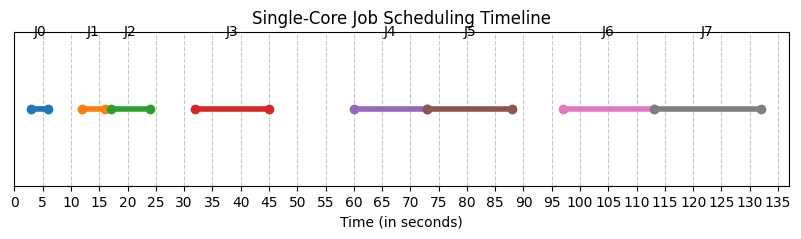

In [ ]:
# Gantt chart
fig, ax = plt.subplots(figsize=(10, 2))

for i in range(len(start_times)):
    ax.plot([start_times[i], completion_times[i]], [1, 1], marker="o", linewidth=4, label=f"Job {i}" if i == 0 else "")
    ax.text((start_times[i] + completion_times[i]) / 2, 1.05, f"J{i}", ha="center", va="bottom", fontsize=10)

ax.set_yticks([])
ax.set_xticks(np.arange(0, max(completion_times) + 5, 5))
ax.set_xlabel("Time (in seconds)")
ax.set_title("Single-Core Job Scheduling Timeline")
ax.set_xlim(0, max(completion_times) + 5)
ax.grid(axis="x", linestyle="--", alpha=0.7)
plt.show()

### Analysis/Discussion

## Multi-core

Now, we will implement a multi-core processor capable of optimizing waiting times

We will reuse some of the code used above for this implementation. Here are some new variables being introduced
- `K`: Since this is a multi core CPU, we can modify the number of cores we wish to run.
- `Z`: This will be used to define precendence relationships between jobs, it only contains binary variables. It is a $N$ x $N$ matrix, in other words, $Z_{i,j} = 1$ means that job $i$ needs to be completed before job $j$ starts.
  - For example: if job $i$ precedes job $j$, then $Z_{i, j} = 1$ and $Z_{j, i} = 0$ and vice-versa
- `incidence_matrix` $A$: It is a matrix that represents the assignment of jobs to cores. This will be a $K$ (# of cores) x $N$ (# of jobs) matrix. In other words, $A_{k,i}=1$ means that job $i$ is assigned to core $k$.

In [ ]:
random.seed(1)

# Number of cores
K = 3

R = np.array([1,2,3,4,5,6,7,8,9,10])
p = np.array(random.sample(range(100),10))

# Number of jobs
N = len(R)

In [ ]:
# Decision variables
S = cp.Variable(N)
C = cp.Variable(N)
Z = cp.Variable((N, N), boolean=True)
A = cp.Variable((K, N), boolean=True)  # Job assignment matrix

Again, some fundamental constraints have been carried over from the single core optimization problem. Here are the new ones introduced:

- Job assigment constraint (`cp.sum(A[:, i]) == 1`): This ensures that each job $i$ is assigned to exactly **one** core. The `A[:, i]` selects the column corresponding to job $i$ in the incidence matrix. The `cp.sum()` function calculates the sum of elements in this column. By setting this sum to 1, we enforce that only one core is assigned to each job.

- Core-based precedence Constraints (using M): Briefly, in this constraint, we make sure that overlapping of jobs doesn't happen in any of the cores. We will implement this using big M method. Here's the code explanation
  - Nested Loops: The code iterates through cores $k$, jobs $i$, and subsequent jobs $j$ to define precedence relationships and we make sure that jobs $i$ and j are not the same task.
  - Now, we iterate through every job with every other job and enforcing the following constraints:
    - Scenario 1: Jobs $i$ and $j$ on the same core, and $Z_{i,j} = 1$ or $Z_{j,i} = 0$ (job $i$ precedes job $j$)
      - Then job $j$ can only start after job $i$ is completed ($S_{j} \geq C_{i}$).
      - The second constraint becomes trivial since ($S_{i} \geq C_{j} - M$) will always be satisfied as long as $M = C{j} - S{i}$

    - Scenario 2: Jobs $i$ and $j$ on the same core, and $Z{j, i} = 1$ or $Z_{i, j} = 0$ (job $j$ precedes job $i$)
      - The second constraint becomes effective: $S_{i} \geq C_{j}$, ensuring job $i$ starts after job $j$ completes.
      - The first constraint becomes trivial.
      - Kind of the opposite of the first scenario

    - Scenario 3: Jobs $i$ and $j$ are on different cores, regardless of $Z$
      - The constraints become disabled, since it satisfies both constrains by a large margin $M$, hence becoming trivial

  - The third constraint only makes sure that only one or the other $Z_{i, j} + Z_{j, i}$ is satisfied only.

To ensure that task precedence is core-exclusive, the Big-M formulation ensures that:
- (i) Precedence constraints are activated only when tasks share a core.
- (ii) The binary variable $Z_{i,j}$ guarantees that only one precedence direction is chosen between any two tasks.

In conclusion:
- The incidence matrix acts as a filter, ensuring that precedence constraints are applied only when jobs share the same core.
- The Big-M formulation effectively disables constraints when tasks are on different cores, preventing unnecessary constraints.
- The binary variable $Z_{i,j}$ ensures that only one precedence direction is enforced between any two tasks.

In [ ]:
constraints = []

for i in range(N):
    constraints.append(S[i] >= R[i])

for i in range(N):
    constraints.append(C[i] == S[i] + p[i])

for i in range(N):
    constraints.append(cp.sum(A[:, i]) == 1)

for i in range(N):
    constraints.append(S[i] >= R[i])

# Core-based precedence constraints using big-M
M = 500  # Large enough upper bound

for k in range(K):
    for i in range(N):
        for j in range(N):
            if (i!=j):
                constraints.append(S[j] >= C[i] - M * (1 - Z[i, j]) - 2*M * (1 - A[k, i]) -2* M * (1 - A[k, j]))
                constraints.append(S[i] >= C[j] - M * Z[i, j] - 2*M * (1 - A[k, i]) -2*M * (1 - A[k, j]))
                constraints.append(Z[i, j] + Z[j, i] <= 1)  # Only one order is valid

The objective function remains the same. However, we will use a more powerful solver to minimize the compute time using the GUROBI solver. More details can be found here [GUROBI]: https://www.gurobi.com/

In [ ]:
objective = cp.Minimize(cp.sum(S - R))
prob = cp.Problem(objective, constraints)
prob.solve(solver=cp.GUROBI, verbose=True, warm_start=True, reoptimize=True)

start_times = np.round(S.value, decimals=0)
completion_times = np.round(C.value, decimals=0)
assignments = np.round(A.value)

print("Start Times:", start_times)
print("Completion Times:", completion_times)
print("Core Assignments:", assignments)

                                     CVXPY                                     
                                     v1.6.3                                    
(CVXPY) Mar 30 05:12:58 PM: Your problem has 150 variables, 850 constraints, and 0 parameters.
(CVXPY) Mar 30 05:12:58 PM: It is compliant with the following grammars: DCP, DQCP
(CVXPY) Mar 30 05:12:58 PM: (If you need to solve this problem multiple times, but with different data, consider using parameters.)
(CVXPY) Mar 30 05:12:58 PM: CVXPY will first compile your problem; then, it will invoke a numerical solver to obtain a solution.
(CVXPY) Mar 30 05:12:58 PM: Your problem is compiled with the CPP canonicalization backend.
-------------------------------------------------------------------------------
                                  Compilation                                  
-------------------------------------------------------------------------------
(CVXPY) Mar 30 05:12:58 PM: Compiling problem (target solver=GUROBI).

Finally, again we plot the Gantt chart

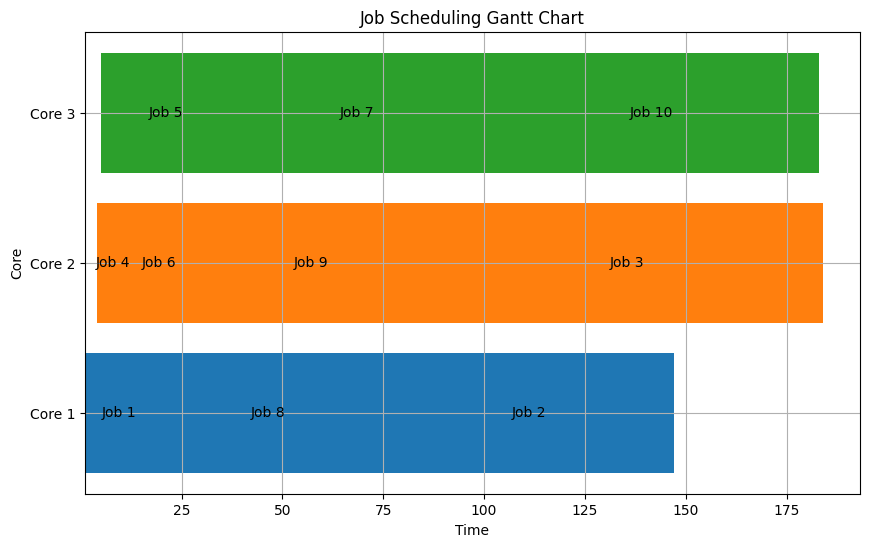

In [ ]:
# Gantt chart plotting
fig, ax = plt.subplots(figsize=(10, 6))

# Colors for cores
core_colors = list(mcolors.TABLEAU_COLORS.values())

for job in range(N):
    core_assigned = np.argmax(assignments[:, job])  # Find the core assigned to the job
    ax.barh(core_assigned, completion_times[job] - start_times[job], left=start_times[job], height=0.8, color=core_colors[core_assigned])
    ax.text(start_times[job] + (completion_times[job] - start_times[job]) / 2, core_assigned, f'Job {job+1}',
            ha='center', va='center', color='black')

ax.set_xlabel('Time')
ax.set_ylabel('Core')
ax.set_title('Job Scheduling Gantt Chart')
ax.set_yticks(np.arange(K))
ax.set_yticklabels([f'Core {i+1}' for i in range(K)])
ax.grid(True)
plt.show()

### Analysis/Discussion

## Greedy algorithm implementation (Multi-core)
One flaw of the above solver is that we assume the algorithm already knows the future, i.e we assume it already knows at t=0 when every task is going to be released, which is impossible to implement in an actual processor.To address this, we refine our approach by implementing a greedy scheduling algorithm that solves the LP in smaller batches. This method better reflects real-world processor behavior, where scheduling decisions are made incrementally as new tasks become available.

#### **Batch Processing Logic:**  
1. **Select Tasks**: The algorithm selects the **earliest \( batch_size\)** tasks based on their release times.  
2. **Solve LP**: The selected batch is processed using the LP solver.  
3. **Update Task Statuses**:  
   - **Completed Tasks**: Removed from the scheduling queue.  
   - **In-Progress Tasks**: Fixed in place for the next iteration.  
   - **Unscheduled Tasks**: If the task has not started by the time new batch is chosen, old tasks are retried alongside newver ones.  
4. **Repeat Until Done**: The process continues iteratively until:  
   - All tasks are scheduled, or  
   - No further progress is possible.

#### **Fixed tasks constraints:**
- For every new linear program, previous lp tasks that have started before new batch is selected but have not yet ended are considered to be fixed in place and the newer batch tasks have to obey the extra constraints:            (`constraints.append(S[i] >= fixed_tasks[task]`)  



                                     CVXPY                                     
                                     v1.6.3                                    
(CVXPY) Mar 30 05:13:28 PM: Your problem has 50 variables, 195 constraints, and 0 parameters.
(CVXPY) Mar 30 05:13:28 PM: It is compliant with the following grammars: DCP, DQCP
(CVXPY) Mar 30 05:13:28 PM: (If you need to solve this problem multiple times, but with different data, consider using parameters.)
(CVXPY) Mar 30 05:13:28 PM: CVXPY will first compile your problem; then, it will invoke a numerical solver to obtain a solution.
(CVXPY) Mar 30 05:13:28 PM: Your problem is compiled with the CPP canonicalization backend.
-------------------------------------------------------------------------------
                                  Compilation                                  
-------------------------------------------------------------------------------
(CVXPY) Mar 30 05:13:29 PM: Compiling problem (target solver=GUROBI).


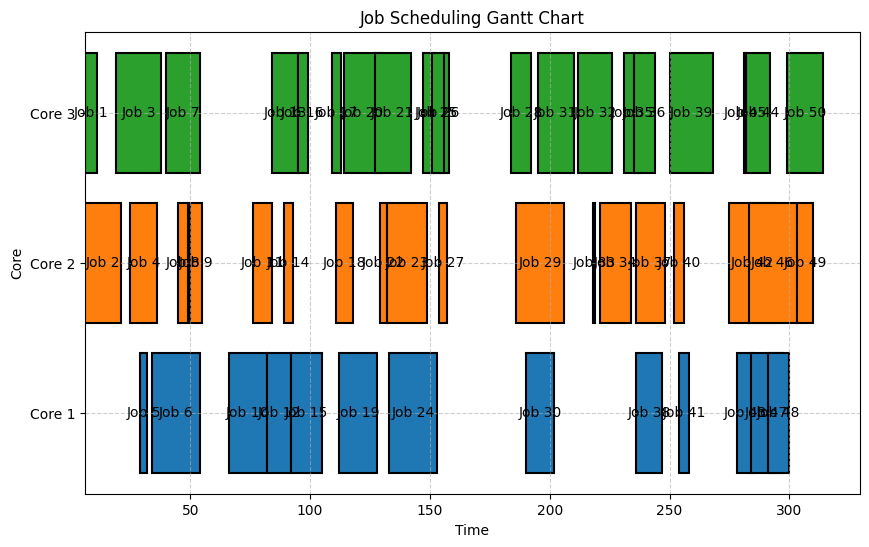

In [ ]:
import numpy as np
import cvxpy as cp
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

random.seed(1)

def solve_lp(task_indices):
    """ Solves the LP for a given subset of tasks."""
    n = len(task_indices)
    S = cp.Variable(n, integer=True)  # Start times
    C = cp.Variable(n, integer=True)  # Completion times
    Z = cp.Variable((n, n), boolean=True)  # Precedence constraints
    incidence_matrix = cp.Variable((K, n), boolean=True)  # Core assignment

    constraints = []

    for i, task in enumerate(task_indices):
        if task in fixed_tasks:
            constraints.append(S[i] >= fixed_tasks[task])  # Ensure it starts after previous batch
        else:
            constraints.append(S[i] >= R[task])
        constraints.append(C[i] == S[i] + p[task])
        constraints.append(cp.sum(incidence_matrix[:, i]) == 1)

    M = 500  # Large upper bound
    for k in range(K):
        for i in range(n):
            for j in range(n):
                if i != j:
                    constraints.append(S[j] >= C[i] - M * (1 - Z[i, j]) - 2 * M * (1 - incidence_matrix[k, i]) - 2 * M * (1 - incidence_matrix[k, j]))
                    constraints.append(S[i] >= C[j] - M * Z[i, j] - 2 * M * (1 - incidence_matrix[k, i]) - 2 * M * (1 - incidence_matrix[k, j]))
                    constraints.append(Z[i, j] + Z[j, i] <= 1)

    objective = cp.Minimize(cp.sum(S - R[task_indices]))
    prob = cp.Problem(objective, constraints)
    prob.solve(solver=cp.GUROBI, verbose=True)

    return np.round(S.value), np.round(C.value), np.round(incidence_matrix.value)

# Number of cores
K = 3  # Updated for multiple cores
M_max = 7  # Max RAM for resource requirement
batch_size = 5  # Number of earliest tasks to schedule per iteration

# Randomly defined release
#np.random.seed(11234)
R = np.sort(np.array(np.random.randint(300, size=50)))
p = np.array(np.random.randint(20, size=50) + 1)
memory = np.array(np.full(15, M_max - 1) + 5)

N = len(R)
remaining_tasks = list(range(N))  # Track remaining tasks
fixed_tasks = {}  # Store tasks that are in progress
completed_tasks = set()

all_start_times = np.full(N, -1)
all_completion_times = np.full(N, -1)
all_assignments = np.zeros((K, N))
previous_remaining_tasks = set(remaining_tasks)

while remaining_tasks:
    current_batch = sorted(remaining_tasks, key=lambda x: R[x])[:batch_size]
    if not current_batch:
        break

    start_times, completion_times, assignments = solve_lp(current_batch)

    new_remaining_tasks = []

    for i, task in enumerate(current_batch):
        if completion_times[i] <= np.max(R):  # Task completed
            completed_tasks.add(task)
        elif start_times[i] == R[task]:  # Task in progress, fix it for the next round
            fixed_tasks[task] = start_times[i]
        elif task in fixed_tasks and completion_times[i] > np.min(R[current_batch]):
            # If task started but not finished by next batch, keep it fixed
            fixed_tasks[task] = start_times[i]
        else:  # Task not started, retry in next iteration
            new_remaining_tasks.append(task)

        all_start_times[task] = start_times[i]
        all_completion_times[task] = completion_times[i]
        all_assignments[:, task] = assignments[:, i]

    # Update remaining tasks
    remaining_tasks = [t for t in remaining_tasks if t not in completed_tasks]
    remaining_tasks.extend(new_remaining_tasks)

    # Move fixed tasks to completed when done
    for task in list(fixed_tasks.keys()):
        if all_completion_times[task] <= np.max(R):
            completed_tasks.add(task)
            del fixed_tasks[task]

    # Stop if no progress is made
    if set(remaining_tasks) == previous_remaining_tasks:
        print("No further progress possible, stopping iteration.")
        break

    previous_remaining_tasks = set(remaining_tasks)

# Gantt chart plotting
fig, ax = plt.subplots(figsize=(10, 6))
core_colors = list(mcolors.TABLEAU_COLORS.values())

for job in range(N):
    core_assigned = np.argmax(all_assignments[:, job])
    if all_start_times[job] >= 0:
        ax.barh(core_assigned, all_completion_times[job] - all_start_times[job],
                left=all_start_times[job], height=0.8, color=core_colors[core_assigned],
                edgecolor='black', linewidth=1.5)
        ax.text(all_start_times[job] + (all_completion_times[job] - all_start_times[job]) / 2,
                core_assigned, f'Job {job+1}', ha='center', va='center', color='black')

ax.set_xlabel('Time')
ax.set_ylabel('Core')
ax.set_title('Job Scheduling Gantt Chart')
ax.set_yticks(np.arange(K))
ax.set_yticklabels([f'Core {i+1}' for i in range(K)])
ax.grid(True, linestyle='--', alpha=0.6)
plt.show()

## Results
The plot shows distribution of optimal total times for 100 trials (50 tasks with randomized p and R):
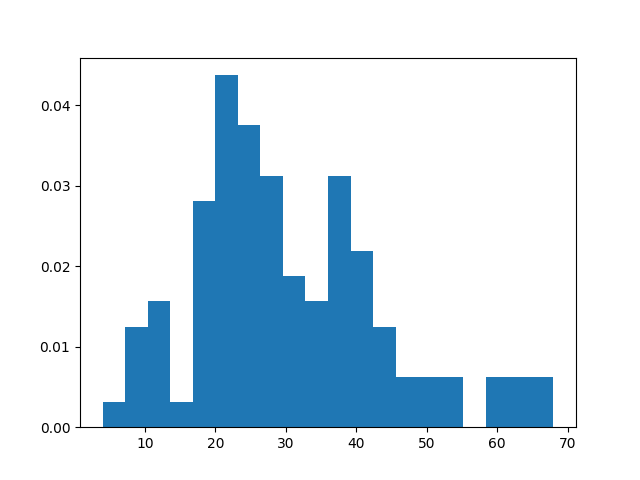

NOTE: Waiting time


# **Comparison of Variable and Constraint Growth: Full LP vs. Greedy LP**
We compares the growth of decision variables and constraints as \(N\) increases for:
- **Original Full LP Approach** (solving all tasks at once)
- **Greedy LP Approach** (solving in increments of batch_size, e.g., 5)

---

## **1. Growth Analysis**
### **1.1 Original Full LP (One Solve)**
For \(N\) tasks:
- **Total Variables**: \(O(N^2)\)
- **Total Constraints**: \(O(N^2)\)
- Memory usage and computation time scale in polynomial time.

### **1.2 Greedy LP (Batch Solve, Iterative)**
With a batch size of \(B\):
- **Per Iteration Variables**: \(O(B^2)\)
- **Per Iteration Constraints**: \(O(B^2)\)
- **Total Variables Over All Iterations**: \(O(NB)\)
- **Total Constraints Over All Iterations**: \(O(NB)\)
- More scalable since each LP solve is smaller.


We observe that when  running our code on a laptop, the original lp can only be solved for up to N =22 in reasonable time, as opposed to N = 1000  for the greedy lp.

---

## **2. Implementation & Visualization**
We plot how variable and constraint growth differs for increasing \(N\).


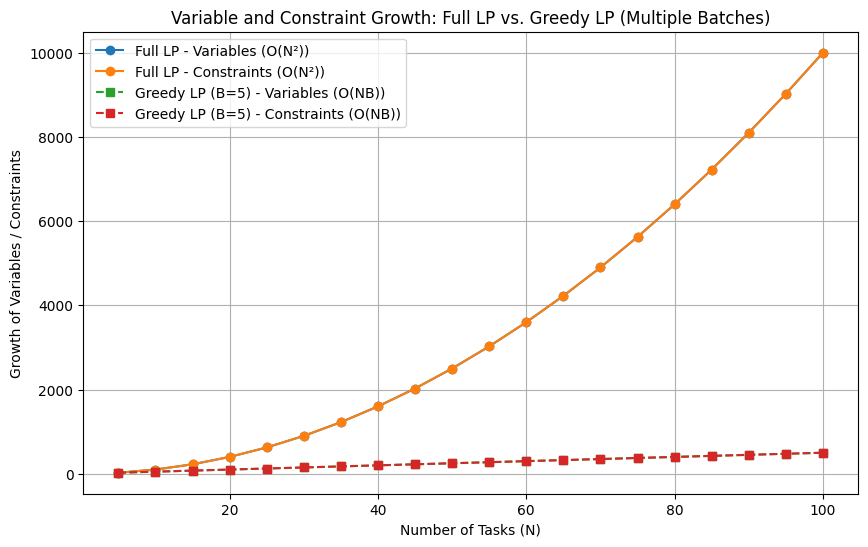

In [ ]:
N_values = np.arange(5, 101, 5)
batch_sizes = [5]

original_variables = N_values**2
original_constraints = N_values**2

plt.figure(figsize=(10, 6))

plt.plot(N_values, original_variables, label="Full LP - Variables (O(N²))", linestyle='-', marker='o')
plt.plot(N_values, original_constraints, label="Full LP - Constraints (O(N²))", linestyle='-', marker='o')

for B in batch_sizes:
    greedy_variables = N_values * B
    greedy_constraints = N_values * B
    plt.plot(N_values, greedy_variables, label=f"Greedy LP (B={B}) - Variables (O(NB))", linestyle='--', marker='s')
    plt.plot(N_values, greedy_constraints, label=f"Greedy LP (B={B}) - Constraints (O(NB))", linestyle='--', marker='s')

plt.xlabel("Number of Tasks (N)")
plt.ylabel("Growth of Variables / Constraints")
plt.title("Variable and Constraint Growth: Full LP vs. Greedy LP (Multiple Batches)")
plt.legend()
plt.grid(True)
plt.show()

## Bibliography

- https://www.mathworks.com/help/optim/ug/integer-logical-modeling.html (Big M)